# Figure S7 · Schaefer100: network-level session contrasts

In [1]:
from pathlib import Path
import pickle
import sys
import os
import matplotlib.pyplot as plt
import numpy as np
base_path = next(
    p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
    if (p / "CODE").is_dir() and (p / "DATA").is_dir()
)
sys.path.insert(0, str(Path(base_path) / 'CODE'))

## Within Network tests

In [2]:
# Data parameters
results_path = f"{base_path}/RESULTS/replication_dataset/network_within_task/analysis_results.pkl"

output_path = f"{base_path}/FIGURES/supplementary/Fig_S7"
os.makedirs(output_path, exist_ok=True)

# plotting parameters
TEXTSIZE = 18
TICKSIZE = 14
LABELSIZE = 16
TITLESIZE = 16
vmin, vmax = -0.15, 0.15

In [3]:
from utils.contrasts import build_plot_matrix

# Functions

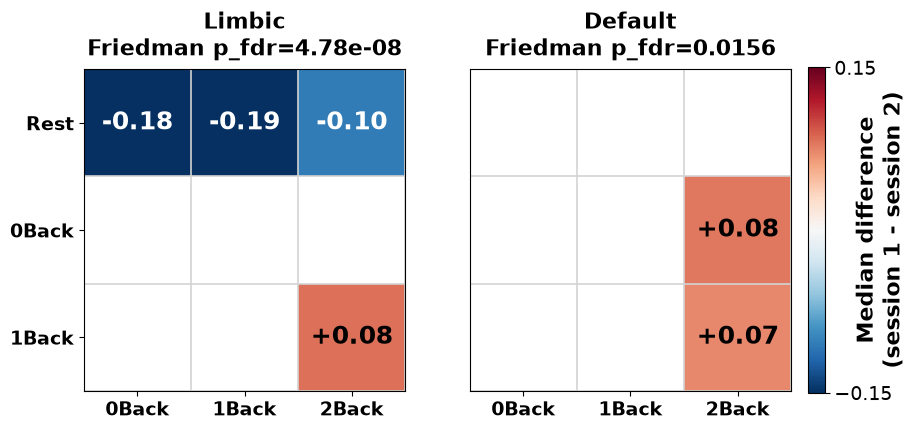

In [4]:
# Load results
with open(results_path, "rb") as f:
    payload = pickle.load(f)

overall_df = payload["overall_df"]
pairwise_df = payload["pairwise_df"]
sig_networks = payload["sig_networks"]
plot_rows = payload["plot_rows"]
plot_cols = payload["plot_cols"]
session_order = payload["session_order"]
overall_correction = payload["overall_correction"]
pairwise_correction = payload["pairwise_correction"]
p_val_sig = payload["p_val_sig"]


# color scale

if vmin is None or vmax is None:
    all_display_vals = []
    for net in sig_networks:
        pair_df_net = pairwise_df[pairwise_df["Network"] == net].copy()
        mat, _ = build_plot_matrix(pair_df_net, plot_rows, plot_cols, session_order, only_significant=True)
        all_display_vals.extend(mat[~np.isnan(mat)].ravel())

    absmax = np.max(np.abs(all_display_vals)) if len(all_display_vals) > 0 else 1.0
    vmin = -absmax
    vmax = absmax

# plot
if len(sig_networks) == 0:
    print("No significant networks.")
else:
    fig, axes = plt.subplots(
        1, len(sig_networks),
        figsize=(5.5 * len(sig_networks), 4.8),
        squeeze=False
    )
    axes = axes[0]

    cmap = plt.get_cmap("RdBu_r").copy()
    cmap.set_bad(color="white")

    im = None

    count = 0
    for ax, net in zip(axes, sig_networks):
        count += 1
        pair_df_net = pairwise_df[pairwise_df["Network"] == net].copy()
        mat, annot = build_plot_matrix(
            pair_df_net,
            plot_rows=plot_rows,
            plot_cols=plot_cols,
            session_order=session_order,
            only_significant=True
        )
        masked = np.ma.masked_invalid(mat)

        im = ax.imshow(
            masked,
            cmap=cmap,
            vmin=vmin,
            vmax=vmax,
            aspect="equal"
        )

        # ticks
        ax.set_xticks(np.arange(len(plot_cols)))
        ax.set_xticklabels(plot_cols, fontsize=TICKSIZE, fontweight="bold")
        if count == 1:
            ax.set_yticks(np.arange(len(plot_rows)))
            ax.set_yticklabels(plot_rows, fontsize=TICKSIZE, fontweight="bold")
        else:
            ax.set_yticks([])
        
        # grid
        ax.set_xticks(np.arange(-0.5, len(plot_cols), 1), minor=True)
        ax.set_yticks(np.arange(-0.5, len(plot_rows), 1), minor=True)
        ax.grid(which="minor", color="lightgray", linestyle="-", linewidth=1.2)
        ax.tick_params(which="minor", bottom=False, left=False)

        # title with overall q
        row_overall = overall_df[overall_df["Network"] == net].iloc[0]
        qtxt = row_overall["q"]

        ax.set_title(
            f"{net}\nFriedman p_fdr={qtxt:.3g}",
            fontsize=TITLESIZE,
            fontweight="bold",
            pad=10
        )

        # annotations
        for i in range(mat.shape[0]):
            for j in range(mat.shape[1]):
                if np.isnan(mat[i, j]):
                    continue
                val = float(np.round(mat[i, j], 2))
                color = "white" if abs(val) > 0.55 * vmax else "black"
                ax.text(
                    j, i, annot[i, j],
                    ha="center", va="center",
                    fontsize=TEXTSIZE, fontweight="bold",
                    color=color
                )

    cbar = fig.colorbar(im, ax=axes.ravel().tolist(), shrink=0.88, pad=0.02)
    cbar.set_label("Median difference\n(session 1 - session 2)", fontsize=LABELSIZE, fontweight="bold", labelpad=-28)
    cbar.set_ticks([vmin, vmax])
    cbar.ax.tick_params(labelsize=TICKSIZE)

    # Save the figure
plt.savefig(f"{output_path}/network_comparisons_schaefer100.png", dpi=300, bbox_inches="tight")